<a href="https://colab.research.google.com/github/BinuraA/MMA3001-Occupancy-Prediction/blob/main/notebooks/occupancy_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Project Overview

This project investigates whether machine learning can predict university building occupancy using historical sensor measurements. The aim is to predict the occupancy fraction of the next 15-minute interval using recent occupancy patterns and time-related features.

These predictions could potentially support occupancy-aware HVAC scheduling, although the project does not directly estimate energy consumption or control HVAC equipment.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
file_path = (
    '/content/drive/MyDrive/MMA3001_Project/'
    '5occupancySensor_MayToDec2024_9MRows.csv'
)

# Read the first 100,000 rows of the CSV file
df = pd.read_csv(
    file_path,
    nrows=100000
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (100000, 8)

Column names:
['id', 'deviceid', 'floorspaceid', 'occupancystatus', 'headcount', 'collecteddate', 'occupancystatuschangedate', 'previousoccupancystatus']


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-24 00:36:52+11,2023-11-24 00:36:52+11,NotOccupied
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,CurrentlyOccupied
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,NotOccupied
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,RecentlyOccupied
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,CurrentlyOccupied


In [4]:
#Check missing data and errors to check reliability of the measurements
# General dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check occupancy categories
print("\nOccupancy statuses:")
print(df['occupancystatus'].value_counts())

# Check headcount values
print("\nHeadcount statistics:")
print(df['headcount'].describe())

# Check number of devices and spaces
print("\nUnique devices:", df['deviceid'].nunique())
print("Unique spaces:", df['floorspaceid'].nunique())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   id                         100000 non-null  int64 
 1   deviceid                   100000 non-null  object
 2   floorspaceid               100000 non-null  object
 3   occupancystatus            100000 non-null  object
 4   headcount                  100000 non-null  int64 
 5   collecteddate              100000 non-null  object
 6   occupancystatuschangedate  100000 non-null  object
 7   previousoccupancystatus    100000 non-null  object
dtypes: int64(2), object(6)
memory usage: 6.1+ MB

Missing values:
id                           0
deviceid                     0
floorspaceid                 0
occupancystatus              0
headcount                    0
collecteddate                0
occupancystatuschangedate    0
previousoccupancystatus      0
dtype: int64

Oc

In [5]:
# Convert timestamps into usable data
# Convert timestamps
df['collecteddate'] = pd.to_datetime(
    df['collecteddate'],
    utc=True,
    errors='coerce'
).dt.tz_convert('Australia/Melbourne')

# Remove records with invalid timestamps
df = df.dropna(subset=['collecteddate']).copy()

# Extract time information
df['hour'] = df['collecteddate'].dt.hour
df['day_of_week'] = df['collecteddate'].dt.dayofweek

print("Earliest reading:", df['collecteddate'].min())
print("Latest reading:", df['collecteddate'].max())

display(df.head())


Earliest reading: 2023-11-24 00:36:52+11:00
Latest reading: 2024-02-03 16:11:22+11:00


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus,hour,day_of_week
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-24 00:36:52+11:00,2023-11-24 00:36:52+11,NotOccupied,0,4
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-24 00:37:32+11:00,2023-11-24 00:37:32+11,CurrentlyOccupied,0,4
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-24 00:37:32+11:00,2023-11-24 00:37:32+11,NotOccupied,0,4
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-24 00:37:52+11:00,2023-11-24 00:37:52+11,RecentlyOccupied,0,4
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-24 00:37:52+11:00,2023-11-24 00:37:52+11,CurrentlyOccupied,0,4


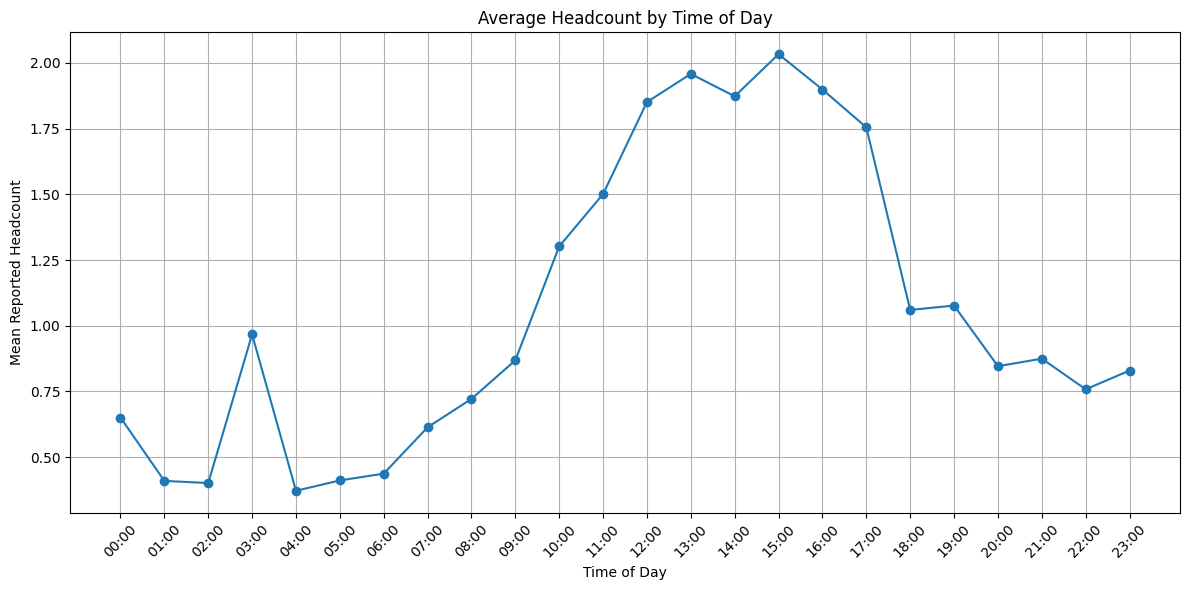

In [6]:
# Visualise occupancy patterns
# Average recorded headcount by hour
hourly_occupancy = df.groupby('hour')['headcount'].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_occupancy.index,
    hourly_occupancy.values,
    marker='o'
)

plt.xlabel('Hour of Day')
plt.ylabel('Mean Reported Headcount')
plt.title('Average Headcount by Hour of Day')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()


Top 10 floor spaces:
floorspaceid
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7    55901
941f0352-bb69-47d0-a9c5-ac29eb4f7319    44099
Name: count, dtype: int64


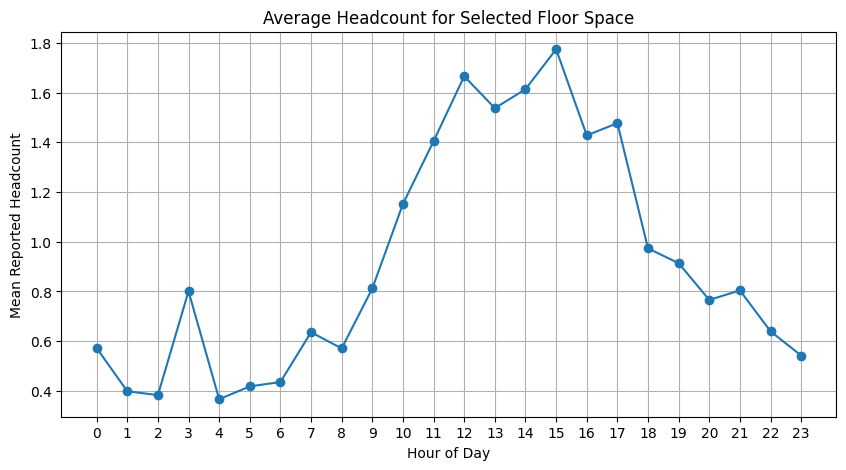

Selected floor space: 0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
Number of readings: 55901


In [7]:

# Identify the floor space with the most readings
space_counts = df['floorspaceid'].value_counts()

print("Top 10 floor spaces:")
print(space_counts.head(10))

# Select the most frequently recorded space
selected_space = space_counts.index[0]

# Filter the data
room_df = df[
    df['floorspaceid'] == selected_space
].copy()

# Calculate average headcount by hour
room_hourly = room_df.groupby('hour')['headcount'].mean()

# Plot the results
plt.figure(figsize=(10, 5))

plt.plot(
    room_hourly.index,
    room_hourly.values,
    marker='o'
)

plt.xlabel('Hour of Day')
plt.ylabel('Mean Reported Headcount')
plt.title('Average Headcount for Selected Floor Space')
plt.xticks(range(24))
plt.grid(True)
plt.show()

print("Selected floor space:", selected_space)
print("Number of readings:", len(room_df))


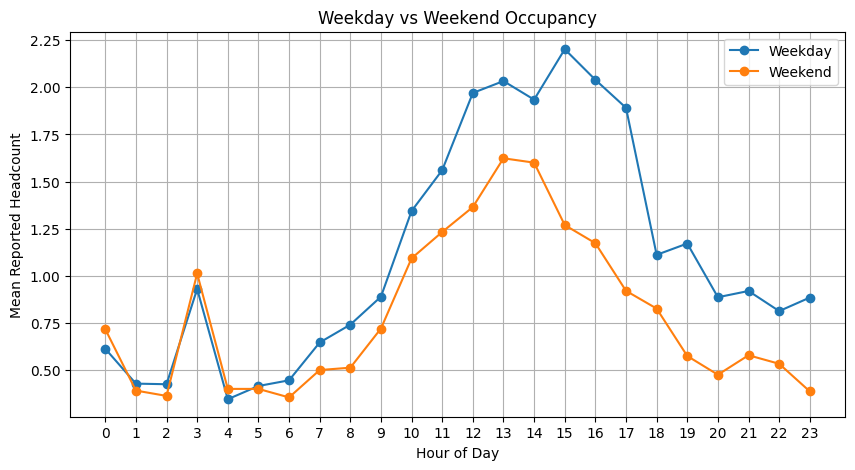

In [8]:

# Create weekday/weekend category
df['day_type'] = np.where(
    df['day_of_week'] < 5,
    'Weekday',
    'Weekend'
)

# Calculate average reported headcount
day_patterns = df.groupby(
    ['hour', 'day_type']
)['headcount'].mean().unstack()

# Plot both patterns
plt.figure(figsize=(10, 5))

for category in day_patterns.columns:
    plt.plot(
        day_patterns.index,
        day_patterns[category],
        marker='o',
        label=category
    )

plt.xlabel('Hour of Day')
plt.ylabel('Mean Reported Headcount')
plt.title('Weekday vs Weekend Occupancy')
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.show()


In [9]:

# Inspect selected floor space
print("Selected floor space:", selected_space)

print("\nNumber of devices:")
print(room_df['deviceid'].nunique())

print("\nDate range:")
print(room_df['collecteddate'].min())
print(room_df['collecteddate'].max())

print("\nOccupancy status distribution:")
print(room_df['occupancystatus'].value_counts())

print("\nNumber of unique recording days:")
print(room_df['collecteddate'].dt.date.nunique())

# Sampling interval for the most common device
selected_device = room_df['deviceid'].value_counts().index[0]

device_df = room_df[
    room_df['deviceid'] == selected_device
].sort_values('collecteddate')

time_gaps = device_df['collecteddate'].diff().dropna()

print("\nMost common time intervals between readings:")
print(time_gaps.value_counts().head(10))


Selected floor space: 0f3f37f8-0335-41e0-ae87-a1d677dfc7d7

Number of devices:
1

Date range:
2023-11-24 00:37:32+11:00
2024-02-03 16:10:42+11:00

Occupancy status distribution:
occupancystatus
CurrentlyOccupied    38507
RecentlyOccupied     10631
NotOccupied           6763
Name: count, dtype: int64

Number of unique recording days:
57

Most common time intervals between readings:
collecteddate
0 days 00:00:20    13713
0 days 00:00:40     8685
0 days 00:00:02     5845
0 days 00:00:04     2624
0 days 00:01:00     2325
0 days 00:00:18     2215
0 days 00:00:16     1736
0 days 00:01:20     1568
0 days 00:00:06     1404
0 days 00:00:22     1055
Name: count, dtype: int64


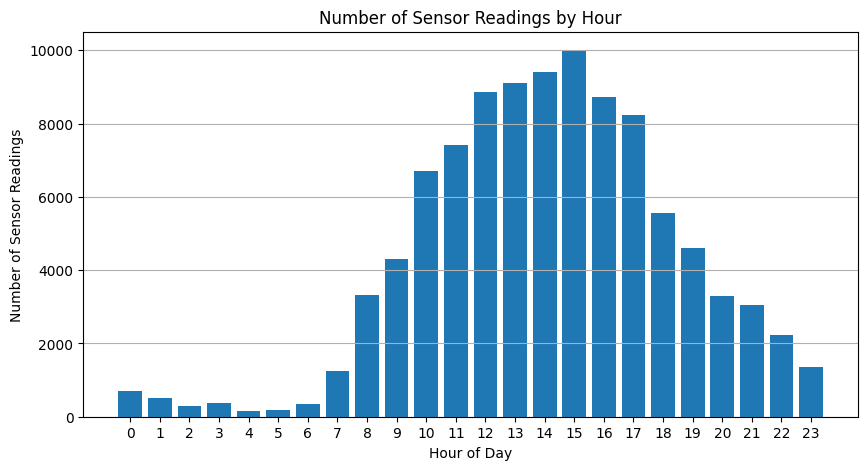

In [10]:

# Count sensor readings by hour
hourly_counts = df.groupby('hour').size()

plt.figure(figsize=(10, 5))

plt.bar(
    hourly_counts.index,
    hourly_counts.values
)

plt.xlabel('Hour of Day')
plt.ylabel('Number of Sensor Readings')
plt.title('Number of Sensor Readings by Hour')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()


In [11]:

# Filter readings between 3 am and 4 am
three_am = df[df['hour'] == 3].copy()

print("Number of 3 am readings:", len(three_am))

print("\nOccupancy status counts:")
print(three_am['occupancystatus'].value_counts())

print("\nHeadcount statistics:")
print(three_am['headcount'].describe())

print("\nDevices producing 3 am readings:")
print(three_am['deviceid'].value_counts().head(10))

# Number of distinct days
print("\nNumber of dates with 3 am readings:")
print(three_am['collecteddate'].dt.date.nunique())


Number of 3 am readings: 364

Occupancy status counts:
occupancystatus
CurrentlyOccupied    204
RecentlyOccupied      87
NotOccupied           73
Name: count, dtype: int64

Headcount statistics:
count    364.000000
mean       0.967033
std        1.107953
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: headcount, dtype: float64

Devices producing 3 am readings:
deviceid
56923747-b390-4f2a-8930-808429132266    364
Name: count, dtype: int64

Number of dates with 3 am readings:
28


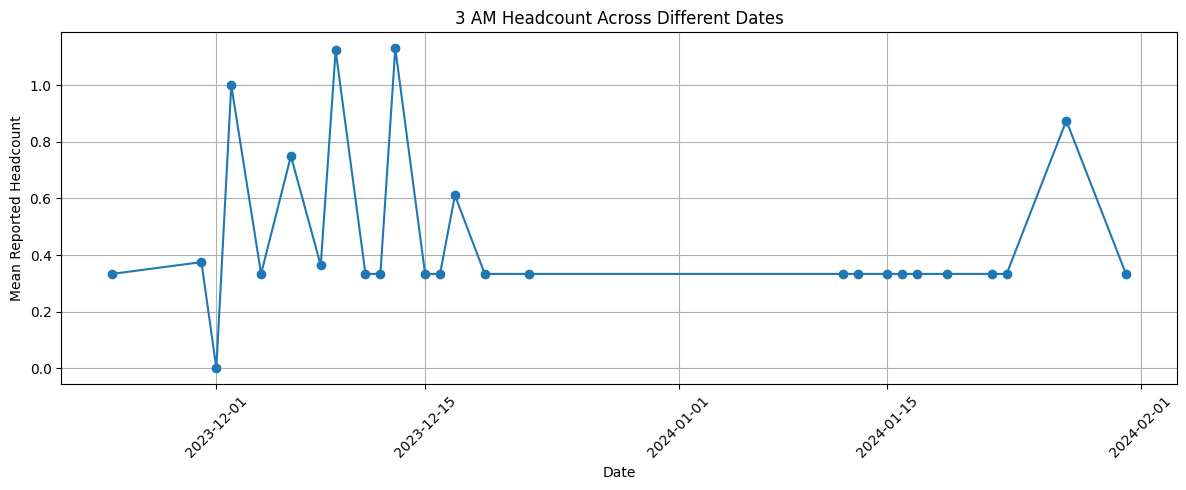

In [12]:

# Focus on the selected floor space
three_am_room = room_df[
    room_df['collecteddate'].dt.hour == 3
].copy()

three_am_room['date'] = (
    three_am_room['collecteddate'].dt.date
)

daily_3am = three_am_room.groupby('date')['headcount'].mean()

plt.figure(figsize=(12, 5))
plt.plot(
    daily_3am.index,
    daily_3am.values,
    marker='o'
)

plt.xlabel('Date')
plt.ylabel('Mean Reported Headcount')
plt.title('3 AM Headcount Across Different Dates')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

# Find all floor spaces associated with the selected device
device_spaces = df[
    df['deviceid'] == selected_device
].groupby('floorspaceid').agg(
    readings=('headcount', 'size'),
    mean_headcount=('headcount', 'mean'),
    first_reading=('collecteddate', 'min'),
    last_reading=('collecteddate', 'max')
)

display(device_spaces)


,readings,mean_headcount,first_reading,last_reading
floorspaceid,,,,
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,55901,1.277830,2023-11-24 00:37:32+11:00,2024-02-03 16:10:42+11:00
941f0352-bb69-47d0-a9c5-ac29eb4f7319,44099,1.794213,2023-11-24 00:36:52+11:00,2024-02-03 16:11:22+11:00


/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = dates.dt.to_period('M').value_counts()
/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = dates.dt.to_period('M').value_counts()
/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = dates.dt.to_period('M').value_counts()
/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = dates.dt.to_period('M').value_counts()
/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  months = dates.dt.to_period('M').value_counts()
/tmp/ipykernel_2596/2270745677.py:15: UserWarning: Converting to PeriodArray/Index representation wi

,Month,Number of Readings
0,2023-11,15133
1,2023-12,49415
2,2024-01,31958
3,2024-02,91331
4,2024-03,381279
5,2024-04,356543
6,2024-05,702321
7,2024-06,332372
8,2024-07,525196
9,2024-08,761191


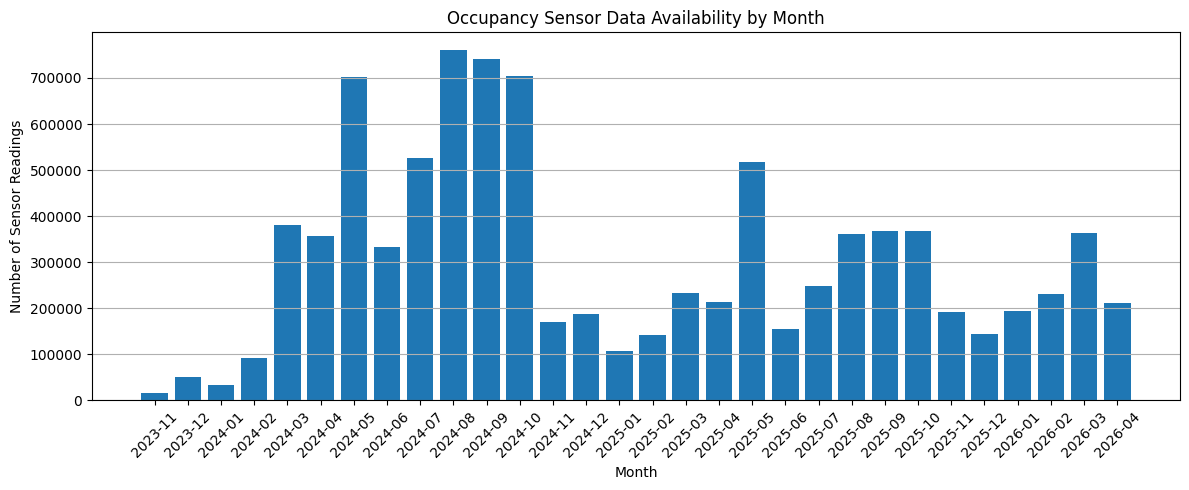

In [14]:

# Read the full ZIP in chunks to avoid memory issues
monthly_counts = {}

for chunk in pd.read_csv(
    file_path,
    compression='zip',
    usecols=['collecteddate'],
    chunksize=200000
):
    dates = pd.to_datetime(
        chunk['collecteddate'],
        utc=True,
        errors='coerce'
    )

    months = dates.dt.to_period('M').value_counts()

    for month, count in months.items():
        monthly_counts[month] = (
            monthly_counts.get(month, 0) + count
        )

monthly_df = pd.DataFrame(
    sorted(monthly_counts.items()),
    columns=['Month', 'Number of Readings']
)

monthly_df['Month'] = monthly_df['Month'].astype(str)

display(monthly_df)

plt.figure(figsize=(12, 5))
plt.bar(
    monthly_df['Month'],
    monthly_df['Number of Readings']
)

plt.xlabel('Month')
plt.ylabel('Number of Sensor Readings')
plt.title('Occupancy Sensor Data Availability by Month')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


### Selection of the Analysis Period

The initial data exploration was used to understand the dataset structure and investigate irregular sensor reporting patterns.

For the main analysis, the period from 22 July to 18 October 2024 was selected to focus on occupancy during Semester 2. This provides a more relevant period for investigating university building usage compared with the initial sample, which included non-teaching periods.

In [15]:

# Select Semester 2, 2024
start_date = pd.Timestamp(
    '2024-07-22',
    tz='Australia/Melbourne'
)

end_date = pd.Timestamp(
    '2024-10-19',
    tz='Australia/Melbourne'
)

matching_chunks = []

for chunk in pd.read_csv(
    file_path,
    compression='zip',
    chunksize=200000
):
    chunk['collecteddate'] = pd.to_datetime(
        chunk['collecteddate'],
        utc=True,
        errors='coerce'
    ).dt.tz_convert('Australia/Melbourne')

    # Same floor space, during Semester 2
    matching = chunk[
        (chunk['floorspaceid'] == selected_space) &
        (chunk['collecteddate'] >= start_date) &
        (chunk['collecteddate'] < end_date)
    ].copy()

    if not matching.empty:
        matching_chunks.append(matching)

if matching_chunks:
    semester_data = pd.concat(
        matching_chunks,
        ignore_index=True
    )

    print("Semester 2 readings:", len(semester_data))
    print("Number of days:",
          semester_data['collecteddate'].dt.date.nunique())
    print("Number of devices:",
          semester_data['deviceid'].nunique())

    print("\nDate range:")
    print(semester_data['collecteddate'].min())
    print(semester_data['collecteddate'].max())

else:
    semester_data = pd.DataFrame()
    print("No Semester 2 records for this floor space.")


Semester 2 readings: 413218
Number of days: 89
Number of devices: 1

Date range:
2024-07-22 00:53:08+10:00
2024-10-18 23:58:54+11:00


In [16]:

# Sort readings chronologically
semester_data = semester_data.sort_values(
    'collecteddate'
).copy()

# Inspect basic information
print("Total readings:", len(semester_data))

print("\nOccupancy status distribution:")
print(semester_data['occupancystatus'].value_counts())

print("\nHeadcount statistics:")
print(semester_data['headcount'].describe())

print("\nMissing values:")
print(semester_data[
    ['collecteddate', 'occupancystatus', 'headcount']
].isnull().sum())

# Calculate time between observations
semester_data['time_gap'] = (
    semester_data['collecteddate'].diff()
)

print("\nMost common time gaps:")
print(semester_data['time_gap'].value_counts().head(10))

print("\nTime gap statistics:")
print(semester_data['time_gap'].describe())


Total readings: 413218

Occupancy status distribution:
occupancystatus
CurrentlyOccupied    387154
RecentlyOccupied      16730
NotOccupied            9334
Name: count, dtype: int64

Headcount statistics:
count    413218.000000
mean          2.902466
std           3.331102
min           0.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          40.000000
Name: headcount, dtype: float64

Missing values:
collecteddate      0
occupancystatus    0
headcount          0
dtype: int64

Most common time gaps:
time_gap
0 days 00:00:02    208993
0 days 00:00:04     70602
0 days 00:00:06     31311
0 days 00:00:08     16874
0 days 00:00:30     10752
0 days 00:00:10     10485
0 days 00:00:32      7028
0 days 00:00:12      7007
0 days 00:00:14      5228
0 days 00:00:16      3913
Name: count, dtype: int64

Time gap statistics:
count                       413217
mean     0 days 00:00:18.592521604
std      0 days 00:04:51.884709815
min                0 days 00:00:02
25%   

In [17]:

# Compare reported headcount across occupancy states
status_summary = semester_data.groupby(
    'occupancystatus'
)['headcount'].agg(
    ['count', 'min', 'mean', 'median', 'max']
)

display(status_summary)

# Check potentially inconsistent readings
inconsistent = semester_data[
    (
        (semester_data['occupancystatus'] == 'NotOccupied') &
        (semester_data['headcount'] > 0)
    ) |
    (
        (semester_data['occupancystatus'] == 'CurrentlyOccupied') &
        (semester_data['headcount'] == 0)
    )
]

print("Potentially inconsistent readings:", len(inconsistent))

display(inconsistent.head())


,count,min,mean,median,max
occupancystatus,,,,,
CurrentlyOccupied,387154,1,3.097865,2.0,40
NotOccupied,9334,0,0.000000,0.0,0
RecentlyOccupied,16730,0,0.000000,0.0,0


Potentially inconsistent readings: 0


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus,time_gap


### Preparing Occupancy Data for Prediction

The sensor measurements were recorded at irregular intervals, making it necessary to convert them into consistent time intervals.

The occupancy states were first converted into binary indicators. Readings were then resampled into one-minute intervals, with missing states carried forward for a maximum of five minutes. The data was aggregated into 15-minute occupancy fractions, requiring at least 12 valid or filled minutes per interval.

These fractions represent estimates based on sensor states rather than verified building headcounts.

In [18]:

# Create binary occupancy status
valid_statuses = [
    'CurrentlyOccupied',
    'RecentlyOccupied',
    'NotOccupied'
]

clean_data = semester_data[
    semester_data['occupancystatus'].isin(valid_statuses)
].copy()

clean_data['occupied'] = (
    clean_data['occupancystatus'] == 'CurrentlyOccupied'
).astype(int)

# Remove invalid timestamps and duplicate timestamps
clean_data = clean_data.dropna(
    subset=['collecteddate']
)

clean_data = clean_data.drop_duplicates(
    subset=['collecteddate'],
    keep='last'
)

clean_data = clean_data.set_index(
    'collecteddate'
).sort_index()

# Resample into one-minute intervals
minute_occupancy = (
    clean_data['occupied']
    .resample('1min')
    .last()
)

# Carry forward status for up to 2 missing minutes
minute_occupancy = minute_occupancy.ffill(limit=2)

# Aggregate to 15-minute occupancy fractions
occupancy_15min = minute_occupancy.resample('15min').agg(
    ['mean', 'count']
)

occupancy_15min = occupancy_15min.rename(
    columns={
        'mean': 'occupancy_fraction',
        'count': 'valid_minutes'
    }
)

# Only retain intervals with sufficient data
occupancy_15min.loc[
    occupancy_15min['valid_minutes'] < 12,
    'occupancy_fraction'
] = np.nan

print("Total 15-minute intervals:", len(occupancy_15min))

print(
    "Usable intervals:",
    occupancy_15min['occupancy_fraction'].notna().sum()
)

display(occupancy_15min.head(20))


Total 15-minute intervals: 8537
Usable intervals: 4228


,occupancy_fraction,valid_minutes
collecteddate,,
2024-07-22 00:45:00+10:00,NaN,4
2024-07-22 01:00:00+10:00,NaN,0
2024-07-22 01:15:00+10:00,NaN,0
2024-07-22 01:30:00+10:00,NaN,0
2024-07-22 01:45:00+10:00,NaN,0
2024-07-22 02:00:00+10:00,NaN,0
2024-07-22 02:15:00+10:00,NaN,0
2024-07-22 02:30:00+10:00,NaN,0
2024-07-22 02:45:00+10:00,NaN,0


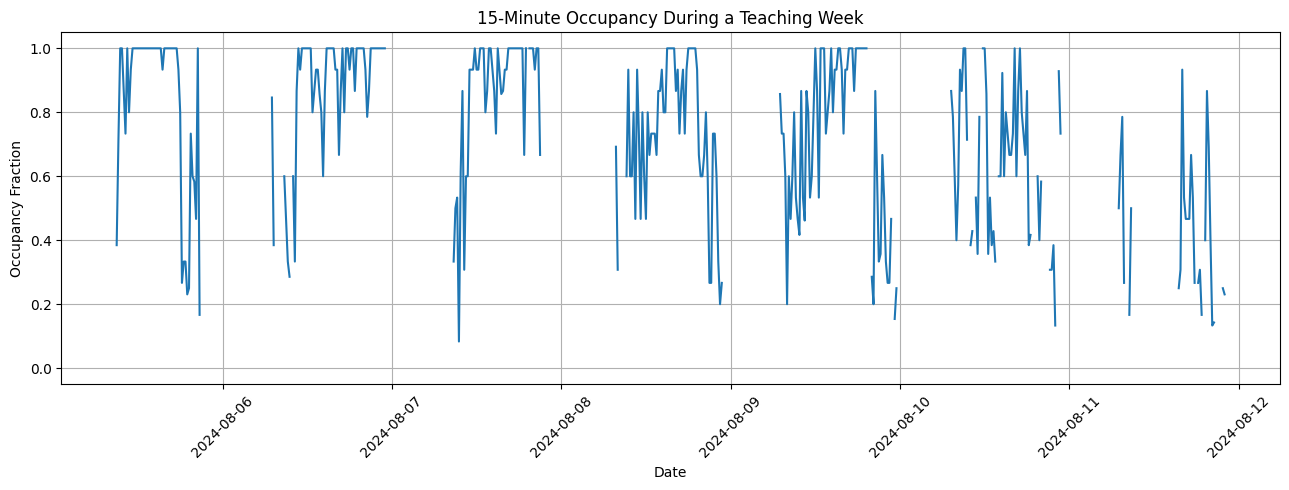

In [19]:

# Select a teaching week
week_data = occupancy_15min.loc[
    '2024-08-05':'2024-08-11'
]

plt.figure(figsize=(13, 5))

plt.plot(
    week_data.index,
    week_data['occupancy_fraction']
)

plt.xlabel('Date')
plt.ylabel('Occupancy Fraction')
plt.title('15-Minute Occupancy During a Teaching Week')

plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:

total_intervals = len(occupancy_15min)

valid_intervals = (
    occupancy_15min['occupancy_fraction']
    .notna()
    .sum()
)

coverage = 100 * valid_intervals / total_intervals

print(f"Total intervals: {total_intervals}")
print(f"Valid intervals: {valid_intervals}")
print(f"Data coverage: {coverage:.2f}%")

# Check availability by month
monthly_coverage = (
    occupancy_15min['occupancy_fraction']
    .notna()
    .resample('MS')
    .mean()
    * 100
)

print("\nMonthly data coverage (%):")
display(monthly_coverage)


Total intervals: 8537
Valid intervals: 4228
Data coverage: 49.53%

Monthly data coverage (%):


,occupancy_fraction
collecteddate,
2024-07-01 00:00:00+10:00,46.603971
2024-08-01 00:00:00+10:00,50.537634
2024-09-01 00:00:00+10:00,47.743056
2024-10-01 00:00:00+10:00,52.378190


,Fill Limit (min),Valid Intervals,Coverage (%)
0,2,4228,49.525594
1,5,4807,56.307836
2,10,5405,63.312639


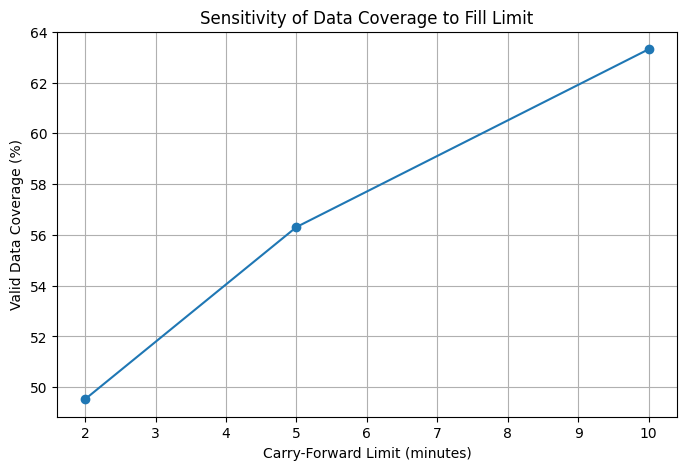

In [21]:

# Compare different carry-forward limits

fill_limits = [2, 5, 10]

coverage_results = []

for limit in fill_limits:

    # Create one-minute occupancy series
    minute_series = (
        clean_data['occupied']
        .resample('1min')
        .last()
    )

    # Carry forward readings
    minute_filled = minute_series.ffill(limit=limit)

    # Aggregate into 15-minute intervals
    interval_data = minute_filled.resample('15min').agg(
        ['mean', 'count']
    )

    valid = interval_data['count'] >= 12

    coverage = 100 * valid.mean()

    coverage_results.append({
        'Fill Limit (min)': limit,
        'Valid Intervals': valid.sum(),
        'Coverage (%)': coverage
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

# Visualise the results
plt.figure(figsize=(8, 5))

plt.plot(
    coverage_df['Fill Limit (min)'],
    coverage_df['Coverage (%)'],
    marker='o'
)

plt.xlabel('Carry-Forward Limit (minutes)')
plt.ylabel('Valid Data Coverage (%)')
plt.title('Sensitivity of Data Coverage to Fill Limit')
plt.grid(True)
plt.show()


In [22]:

# Time until next sensor reading
gap_data = clean_data.copy()

gap_data['next_time'] = (
    gap_data.index.to_series().shift(-1)
)

gap_data['gap_minutes'] = (
    (gap_data['next_time'] - gap_data.index)
    .dt.total_seconds() / 60
)

# Inspect readings followed by gaps over 15 minutes
long_gaps = gap_data[
    gap_data['gap_minutes'] > 15
]

print("Number of gaps longer than 15 minutes:", len(long_gaps))

print("\nStatuses before long gaps:")
print(
    long_gaps['occupancystatus']
    .value_counts()
)

print("\nExample long gaps:")
display(
    long_gaps[
        ['occupancystatus', 'headcount', 'gap_minutes']
    ].head(10)
)


Number of gaps longer than 15 minutes: 657

Statuses before long gaps:
occupancystatus
NotOccupied          591
CurrentlyOccupied     66
Name: count, dtype: int64

Example long gaps:


,occupancystatus,headcount,gap_minutes
collecteddate,,,
2024-07-22 00:54:50+10:00,NotOccupied,0,246.100000
2024-07-22 05:02:44+10:00,NotOccupied,0,117.900000
2024-07-22 07:00:38+10:00,CurrentlyOccupied,1,63.800000
2024-07-22 18:51:46+10:00,CurrentlyOccupied,1,20.166667
2024-07-22 22:22:22+10:00,CurrentlyOccupied,1,39.733333
2024-07-22 23:32:16+10:00,NotOccupied,0,18.633333
2024-07-23 00:20:16+10:00,NotOccupied,0,15.333333
2024-07-23 00:38:00+10:00,NotOccupied,0,49.333333
2024-07-23 01:29:18+10:00,NotOccupied,0,196.666667


In [23]:

# Starting from the clean_data created in Step 6

# Create one-minute series
minute_series = (
    clean_data['occupied']
    .resample('1min')
    .last()
)

# Apply selected fill limit
minute_filled = minute_series.ffill(limit=5)

# Create 15-minute occupancy intervals
occupancy_15min = minute_filled.resample('15min').agg(
    ['mean', 'count']
)

occupancy_15min.columns = [
    'occupancy_fraction',
    'valid_minutes'
]

# Require at least 12 observed/filled minutes
occupancy_15min.loc[
    occupancy_15min['valid_minutes'] < 12,
    'occupancy_fraction'
] = np.nan

print("Usable intervals:",
      occupancy_15min['occupancy_fraction'].notna().sum())

display(occupancy_15min.head())


Usable intervals: 4807


,occupancy_fraction,valid_minutes
collecteddate,,
2024-07-22 00:45:00+10:00,NaN,7
2024-07-22 01:00:00+10:00,NaN,0
2024-07-22 01:15:00+10:00,NaN,0
2024-07-22 01:30:00+10:00,NaN,0
2024-07-22 01:45:00+10:00,NaN,0


In [24]:

# Create machine learning dataset
data = occupancy_15min[['occupancy_fraction']].copy()

# Inputs: latest completed intervals
data['current_occupancy'] = data['occupancy_fraction']
data['previous_occupancy'] = data['occupancy_fraction'].shift(1)

# Target: occupancy fraction 15 minutes ahead
data['target'] = data['occupancy_fraction'].shift(-1)

# Next interval's start time
target_time = data.index + pd.Timedelta(minutes=15)

# Time-based features
data['hour'] = target_time.hour
data['day_of_week'] = target_time.dayofweek
data['weekend'] = (data['day_of_week'] >= 5).astype(int)

# Remove missing inputs and targets
# Keep the regular time grid intact until this step
data = data.dropna().copy()

print("Total model samples:", len(data))

display(data.head())


Total model samples: 4089


,occupancy_fraction,current_occupancy,previous_occupancy,target,hour,day_of_week,weekend
collecteddate,,,,,,,
2024-07-22 08:30:00+10:00,1.000000,1.000000,1.000000,0.933333,8,0,0
2024-07-22 08:45:00+10:00,0.933333,0.933333,1.000000,1.000000,9,0,0
2024-07-22 09:00:00+10:00,1.000000,1.000000,0.933333,1.000000,9,0,0
2024-07-22 09:15:00+10:00,1.000000,1.000000,1.000000,1.000000,9,0,0
2024-07-22 09:30:00+10:00,1.000000,1.000000,1.000000,1.000000,9,0,0


### Model Development and Evaluation

The processed occupancy data was used to create input features, including current occupancy, previous occupancy, hour, day of week and weekend status.

Three prediction approaches were considered: a persistence baseline, Linear Regression and Decision Tree Regression.

The persistence baseline provides a simple comparison by assuming occupancy remains unchanged in the next interval. The machine learning models were evaluated to determine whether they could improve prediction accuracy.

MAE and RMSE were used to compare performance, with RMSE placing greater emphasis on larger prediction errors.

In [25]:

features = [
    'current_occupancy',
    'previous_occupancy',
    'hour',
    'day_of_week',
    'weekend'
]

X = data[features]
y = data['target']

n = len(data)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining dates:", X_train.index.min(), "to", X_train.index.max())
print("Validation dates:", X_val.index.min(), "to", X_val.index.max())
print("Testing dates:", X_test.index.min(), "to", X_test.index.max())


Training samples: 2862
Validation samples: 613
Testing samples: 614

Training dates: 2024-07-22 08:30:00+10:00 to 2024-09-22 12:15:00+10:00
Validation dates: 2024-09-22 15:45:00+10:00 to 2024-10-06 12:00:00+11:00
Testing dates: 2024-10-06 12:15:00+11:00 to 2024-10-18 20:15:00+11:00


In [26]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Decision Tree Regression
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)
tree_model.fit(X_train, y_train)

# Generate predictions
linear_pred = np.clip(
    linear_model.predict(X_val), 0, 1
)

tree_pred = np.clip(
    tree_model.predict(X_val), 0, 1
)

# Baseline prediction: occupancy stays unchanged
baseline_pred = X_val['current_occupancy'].values

print("Models trained successfully!")


Models trained successfully!


In [27]:

def evaluate_model(name, actual, predicted):
    """Return MAE and RMSE for a prediction model."""

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    return {
        'Model': name,
        'MAE': mae,
        'RMSE': rmse
    }


results = [
    evaluate_model('Persistence Baseline', y_val, baseline_pred),
    evaluate_model('Linear Regression', y_val, linear_pred),
    evaluate_model('Decision Tree', y_val, tree_pred)
]

results_df = pd.DataFrame(results)

display(results_df.sort_values('MAE'))


,Model,MAE,RMSE
0,Persistence Baseline,0.122050,0.191368
1,Linear Regression,0.125026,0.173706
2,Decision Tree,0.129612,0.180280


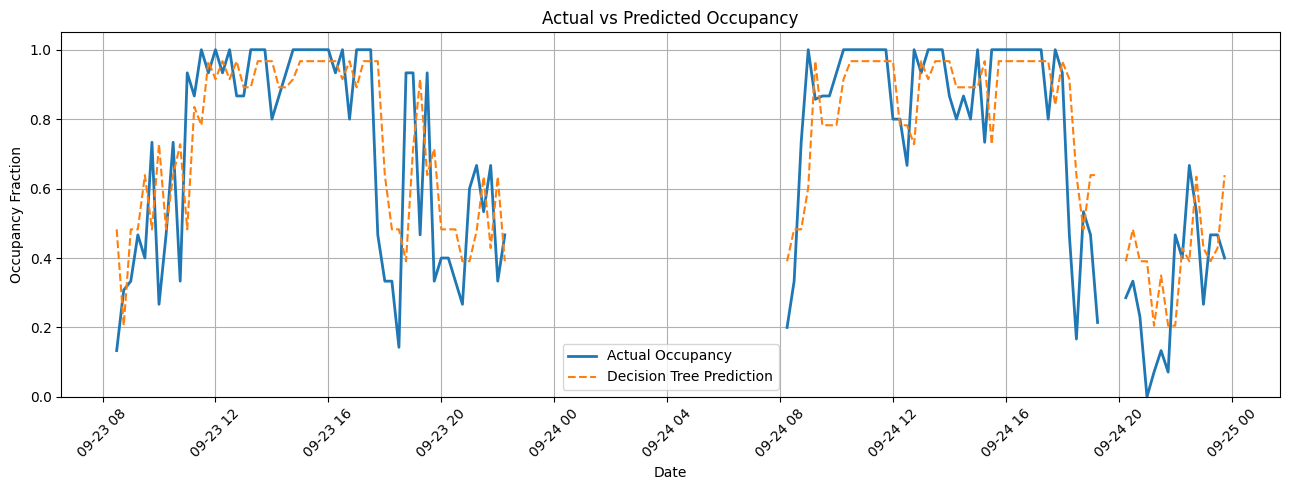

In [28]:

# Create a comparison DataFrame
comparison = pd.DataFrame({
    'Actual': y_val,
    'Predicted': tree_pred
}, index=y_val.index)

# Reindex to the complete 15-minute time grid
full_index = pd.date_range(
    comparison.index.min(),
    comparison.index.max(),
    freq='15min'
)

comparison = comparison.reindex(full_index)

# Select a 2-day period
plot_data = comparison.loc[
    '2024-09-23':'2024-09-24'
]

plt.figure(figsize=(13, 5))

plt.plot(
    plot_data.index,
    plot_data['Actual'],
    label='Actual Occupancy',
    linewidth=2
)

plt.plot(
    plot_data.index,
    plot_data['Predicted'],
    label='Decision Tree Prediction',
    linestyle='--'
)

plt.xlabel('Date')
plt.ylabel('Occupancy Fraction')
plt.title('Actual vs Predicted Occupancy')

plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [29]:
# Found that there is no data in the selected interval so decided to plot another period with more data
# Find the 24-hour period containing the most valid
# prediction samples within the validation dataset.

# One row represents one valid 15-minute prediction
valid_samples = pd.Series(
    1,
    index=y_val.index
)

# Count valid samples in each calendar day
daily_counts = valid_samples.resample('D').sum()

# Find day with highest availability
best_day = daily_counts.idxmax()

print("Best day for visualisation:", best_day.date())
print("Valid prediction samples:", int(daily_counts.max()))
print("Maximum possible per full day:", 96)

# Display availability for all validation days
display(daily_counts.to_frame('Valid Samples'))


Best day for visualisation: 2024-10-03
Valid prediction samples: 65
Maximum possible per full day: 96


,Valid Samples
collecteddate,
2024-09-22 00:00:00+10:00,6
2024-09-23 00:00:00+10:00,56
2024-09-24 00:00:00+10:00,60
2024-09-25 00:00:00+10:00,49
2024-09-26 00:00:00+10:00,55
2024-09-27 00:00:00+10:00,24
2024-09-28 00:00:00+10:00,29
2024-09-29 00:00:00+10:00,10
2024-09-30 00:00:00+10:00,49


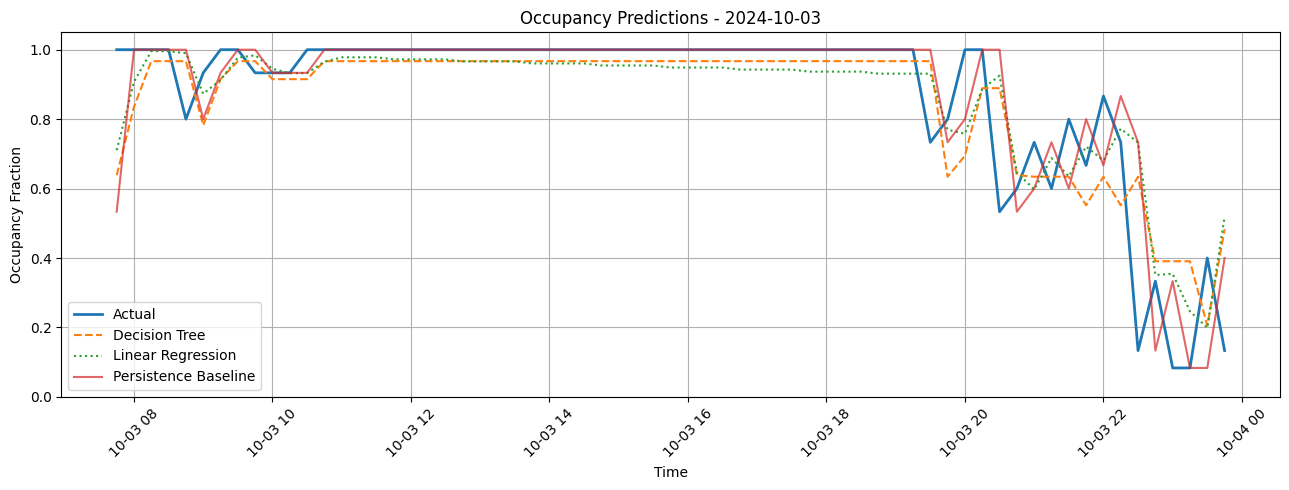

In [30]:

# Combine validation predictions and actual observations
comparison = pd.DataFrame({
    'Actual': y_val,
    'Decision Tree': tree_pred,
    'Linear Regression': linear_pred,
    'Baseline': baseline_pred
}, index=y_val.index)

# Select the best calendar day
day_start = best_day
day_end = best_day + pd.Timedelta(days=1)

plot_data = comparison[
    (comparison.index >= day_start) &
    (comparison.index < day_end)
]

# Reindex to a regular 15-minute grid
# to preserve missing intervals
full_index = pd.date_range(
    start=day_start,
    end=day_end,
    freq='15min',
    inclusive='left'
)

plot_data = plot_data.reindex(full_index)

# Plot all models
plt.figure(figsize=(13, 5))

plt.plot(
    plot_data.index,
    plot_data['Actual'],
    label='Actual',
    linewidth=2
)

plt.plot(
    plot_data.index,
    plot_data['Decision Tree'],
    label='Decision Tree',
    linestyle='--'
)

plt.plot(
    plot_data.index,
    plot_data['Linear Regression'],
    label='Linear Regression',
    linestyle=':'
)

plt.plot(
    plot_data.index,
    plot_data['Baseline'],
    label='Persistence Baseline',
    alpha=0.7
)

plt.xlabel('Time')
plt.ylabel('Occupancy Fraction')
plt.title(
    f'Occupancy Predictions - {best_day.date()}'
)

plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [31]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

# Different tree depths to investigate
depths = [2, 3, 5, 8, 10, 15, 20]

optimisation_results = []

for depth in depths:

    # Create model
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Measure training time
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    # Generate predictions
    train_pred = np.clip(model.predict(X_train), 0, 1)
    val_pred = np.clip(model.predict(X_val), 0, 1)

    # Calculate prediction errors
    train_mae = mean_absolute_error(y_train, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)

    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    # Store results
    optimisation_results.append({
        'Tree Depth': depth,
        'Training MAE': train_mae,
        'Validation MAE': val_mae,
        'Validation RMSE': val_rmse,
        'Training Time (s)': training_time
    })

# Convert to DataFrame
optimisation_df = pd.DataFrame(optimisation_results)

display(optimisation_df)


,Tree Depth,Training MAE,Validation MAE,Validation RMSE,Training Time (s)
0,2,0.137074,0.135183,0.184261,0.004406
1,3,0.131809,0.130755,0.179934,0.003007
2,5,0.122298,0.129612,0.180280,0.003617
3,8,0.100156,0.133657,0.193140,0.004697
4,10,0.077147,0.146079,0.215797,0.005562
5,15,0.033913,0.165457,0.244370,0.007368
6,20,0.025421,0.163053,0.242333,0.008297


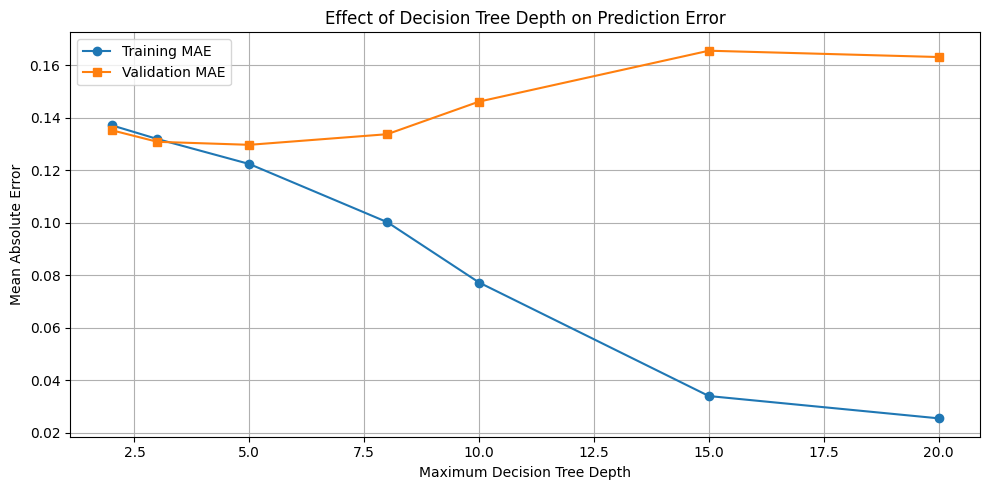

In [32]:

plt.figure(figsize=(10, 5))

plt.plot(
    optimisation_df['Tree Depth'],
    optimisation_df['Training MAE'],
    marker='o',
    label='Training MAE'
)

plt.plot(
    optimisation_df['Tree Depth'],
    optimisation_df['Validation MAE'],
    marker='s',
    label='Validation MAE'
)

plt.xlabel('Maximum Decision Tree Depth')
plt.ylabel('Mean Absolute Error')
plt.title('Effect of Decision Tree Depth on Prediction Error')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


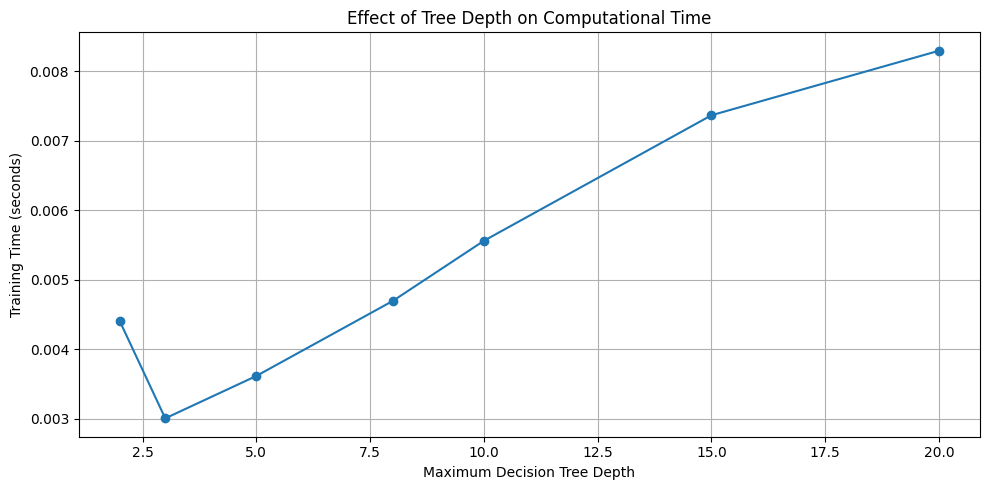

In [33]:

plt.figure(figsize=(10, 5))

plt.plot(
    optimisation_df['Tree Depth'],
    optimisation_df['Training Time (s)'],
    marker='o'
)

plt.xlabel('Maximum Decision Tree Depth')
plt.ylabel('Training Time (seconds)')
plt.title('Effect of Tree Depth on Computational Time')

plt.grid(True)
plt.tight_layout()
plt.show()


In [34]:

# Identify best depth based on validation MAE
best_row = optimisation_df.loc[
    optimisation_df['Validation MAE'].idxmin()
]

best_depth = int(best_row['Tree Depth'])

print("Best Decision Tree depth:", best_depth)

print(
    "Validation MAE:",
    round(best_row['Validation MAE'], 5)
)

print(
    "Validation RMSE:",
    round(best_row['Validation RMSE'], 5)
)

# Train selected model
best_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=42
)

best_tree.fit(X_train, y_train)

print("\nOptimised Decision Tree trained successfully!")


Best Decision Tree depth: 5
Validation MAE: 0.12961
Validation RMSE: 0.18028

Optimised Decision Tree trained successfully!


# ***Improved Validation & Verification ***

The initial models used a chronological 70/15/15 data split.
To provide a more conservative validation approach, a one-hour
separation is introduced between training, validation and testing.

The original results are retained for comparison.




### Improving the Validation Method

An improved chronological split was introduced to reduce the risk of information leakage between training, validation and test periods.

Exclusion gaps were added around the dataset boundaries, and the models were retrained using the revised split.

Decision Tree depth was then reassessed using validation performance. The final test dataset was kept separate from model selection to provide a more independent assessment of prediction accuracy.

In [35]:

 # Improved chronological split

# Use new variable names for improved validation

n = len(data)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_boundary = data.index[train_end]
test_boundary = data.index[val_end]

gap = pd.Timedelta(hours=1)

train_mask = data.index < train_boundary - gap

val_mask = (
    (data.index >= train_boundary + gap) &
    (data.index < test_boundary - gap)
)

test_mask = data.index >= test_boundary + gap

# Create new datasets
X_train_v2 = X.loc[train_mask]
X_val_v2 = X.loc[val_mask]
X_test_v2 = X.loc[test_mask]

y_train_v2 = y.loc[train_mask]
y_val_v2 = y.loc[val_mask]
y_test_v2 = y.loc[test_mask]

print("Improved training samples:", len(X_train_v2))
print("Improved validation samples:", len(X_val_v2))
print("Improved testing samples:", len(X_test_v2))

# Verify chronological separation
assert X_train_v2.index.max() < X_val_v2.index.min()
assert X_val_v2.index.max() < X_test_v2.index.min()

print("Chronological separation verified.")


Improved training samples: 2862
Improved validation samples: 605
Improved testing samples: 610
Chronological separation verified.


In [36]:

# STEP 9B: Retrain models using improved split

linear_model_v2 = LinearRegression()
linear_model_v2.fit(X_train_v2, y_train_v2)

tree_model_v2 = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model_v2.fit(X_train_v2, y_train_v2)

# Generate validation predictions
linear_pred_v2 = np.clip(
    linear_model_v2.predict(X_val_v2), 0, 1
)

tree_pred_v2 = np.clip(
    tree_model_v2.predict(X_val_v2), 0, 1
)

baseline_pred_v2 = X_val_v2[
    'current_occupancy'
].values

# Evaluate models
results_v2 = [
    evaluate_model(
        'Persistence Baseline',
        y_val_v2,
        baseline_pred_v2
    ),
    evaluate_model(
        'Linear Regression',
        y_val_v2,
        linear_pred_v2
    ),
    evaluate_model(
        'Decision Tree',
        y_val_v2,
        tree_pred_v2
    )
]

results_df_v2 = pd.DataFrame(results_v2)

display(results_df_v2)


,Model,MAE,RMSE
0,Persistence Baseline,0.120146,0.189189
1,Linear Regression,0.123271,0.171753
2,Decision Tree,0.127831,0.178250


In [37]:

# STEP 9C: Decision Tree optimisation with improved split

depths = [2, 3, 5, 8, 10, 15, 20]

results_v2 = []

for depth in depths:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_v2, y_train_v2)

    predictions = np.clip(
        model.predict(X_val_v2), 0, 1
    )

    mae = mean_absolute_error(
        y_val_v2, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val_v2, predictions)
    )

    results_v2.append({
        'Tree Depth': depth,
        'Validation MAE': mae,
        'Validation RMSE': rmse
    })

optimisation_v2 = pd.DataFrame(results_v2)

display(optimisation_v2)

# Select best depth using validation MAE
best_depth_v2 = int(
    optimisation_v2.loc[
        optimisation_v2['Validation MAE'].idxmin(),
        'Tree Depth'
    ]
)

print("Best depth:", best_depth_v2)


,Tree Depth,Validation MAE,Validation RMSE
0,2,0.133331,0.181944
1,3,0.128943,0.177624
2,5,0.127831,0.178250
3,8,0.130893,0.189292
4,10,0.143553,0.211441
5,15,0.162860,0.240270
6,20,0.160424,0.238171


Best depth: 5


In [38]:

# STEP 9D: Final test-set evaluation

# Train Decision Tree using the selected depth
best_tree_v2 = DecisionTreeRegressor(
    max_depth=best_depth_v2,
    random_state=42
)

best_tree_v2.fit(X_train_v2, y_train_v2)

# Predictions on untouched test data
baseline_test = X_test_v2['current_occupancy'].values

linear_test = np.clip(
    linear_model_v2.predict(X_test_v2),
    0, 1
)

tree_test = np.clip(
    best_tree_v2.predict(X_test_v2),
    0, 1
)

# Calculate test MAE and RMSE
test_results = [
    evaluate_model(
        'Persistence Baseline',
        y_test_v2,
        baseline_test
    ),
    evaluate_model(
        'Linear Regression',
        y_test_v2,
        linear_test
    ),
    evaluate_model(
        'Optimised Decision Tree',
        y_test_v2,
        tree_test
    )
]

test_results_df = pd.DataFrame(test_results)

print("FINAL TEST RESULTS")
display(test_results_df.sort_values('RMSE'))


FINAL TEST RESULTS


,Model,MAE,RMSE
2,Optimised Decision Tree,0.130425,0.182955
1,Linear Regression,0.131491,0.183799
0,Persistence Baseline,0.126232,0.195851


In [39]:

# Compare validation and test performance

validation_summary = pd.DataFrame({
    'Model': [
        'Persistence Baseline',
        'Linear Regression',
        'Optimised Decision Tree'
    ],
    'Validation MAE': [
        mean_absolute_error(y_val_v2, baseline_pred_v2),
        mean_absolute_error(y_val_v2, linear_pred_v2),
        optimisation_v2.loc[
            optimisation_v2['Tree Depth'] == best_depth_v2,
            'Validation MAE'
        ].iloc[0]
    ],
    'Validation RMSE': [
        np.sqrt(mean_squared_error(y_val_v2, baseline_pred_v2)),
        np.sqrt(mean_squared_error(y_val_v2, linear_pred_v2)),
        optimisation_v2.loc[
            optimisation_v2['Tree Depth'] == best_depth_v2,
            'Validation RMSE'
        ].iloc[0]
    ]
})

final_comparison = validation_summary.merge(
    test_results_df,
    on='Model'
)

final_comparison = final_comparison.rename(
    columns={
        'MAE': 'Test MAE',
        'RMSE': 'Test RMSE'
    }
)

display(final_comparison)


,Model,Validation MAE,Validation RMSE,Test MAE,Test RMSE
0,Persistence Baseline,0.120146,0.189189,0.126232,0.195851
1,Linear Regression,0.123271,0.171753,0.131491,0.183799
2,Optimised Decision Tree,0.127831,0.178250,0.130425,0.182955


In [40]:

# STEP 10A: Create occupancy data using different fill limits

def prepare_occupancy_data(fill_limit):
    """
    Prepare occupancy prediction data from sensor readings.

    Parameters
    ----------
    fill_limit : int
        Maximum number of missing one-minute bins
        to fill using the previous occupancy status.

    Returns
    -------
    pandas.DataFrame
        Model-ready data containing historical occupancy,
        time features and next-interval occupancy target.
    """

    if not isinstance(fill_limit, int) or fill_limit < 0:
        raise ValueError("fill_limit must be a non-negative integer")

    # Resample into one-minute intervals
    minute_series = (
        clean_data['occupied']
        .resample('1min')
        .last()
    )

    # Apply selected carry-forward limit
    minute_filled = minute_series.ffill(limit=fill_limit)

    # Create 15-minute occupancy fractions
    intervals = minute_filled.resample('15min').agg(
        ['mean', 'count']
    )

    intervals.columns = [
        'occupancy_fraction',
        'valid_minutes'
    ]

    # Mark insufficiently observed intervals as missing
    intervals.loc[
        intervals['valid_minutes'] < 12,
        'occupancy_fraction'
    ] = np.nan

    # Build prediction features
    result = intervals[['occupancy_fraction']].copy()

    result['current_occupancy'] = result['occupancy_fraction']
    result['previous_occupancy'] = result['occupancy_fraction'].shift(1)
    result['target'] = result['occupancy_fraction'].shift(-1)

    next_time = result.index + pd.Timedelta(minutes=15)

    result['hour'] = next_time.hour
    result['day_of_week'] = next_time.dayofweek
    result['weekend'] = (result['day_of_week'] >= 5).astype(int)

    return result.dropna().copy()


In [41]:

# STEP 10B: Sensitivity analysis

fill_limits = [2, 5, 10]

features = [
    'current_occupancy',
    'previous_occupancy',
    'hour',
    'day_of_week',
    'weekend'
]

# Use the existing revised validation boundaries
train_cutoff = X_train_v2.index.max()
val_start = X_val_v2.index.min()
val_end = X_val_v2.index.max()

# Prepare each dataset
datasets = {
    limit: prepare_occupancy_data(limit)
    for limit in fill_limits
}

# Use validation timestamps available in every dataset
common_val_times = X_val_v2.index

for dataset in datasets.values():
    common_val_times = common_val_times.intersection(
        dataset.index
    )

print("Common validation samples:", len(common_val_times))

if len(common_val_times) == 0:
    raise ValueError("No common validation samples available")

sensitivity_results = []

for limit, dataset in datasets.items():

    # Training period (same date boundary)
    train_data = dataset.loc[
        dataset.index <= train_cutoff
    ]

    # Identical validation timestamps
    val_data = dataset.loc[common_val_times]

    X_train_s = train_data[features]
    y_train_s = train_data['target']

    X_val_s = val_data[features]
    y_val_s = val_data['target']

    # Train Linear Regression
    model = LinearRegression()
    model.fit(X_train_s, y_train_s)

    # Predict occupancy
    predictions = np.clip(
        model.predict(X_val_s), 0, 1
    )

    # Calculate errors
    mae = mean_absolute_error(y_val_s, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_val_s, predictions)
    )

    sensitivity_results.append({
        'Fill Limit (min)': limit,
        'Training Samples': len(train_data),
        'Validation Samples': len(val_data),
        'MAE': mae,
        'RMSE': rmse
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df)


Common validation samples: 495


,Fill Limit (min),Training Samples,Validation Samples,MAE,RMSE
0,2,2492,495,0.110187,0.154257
1,5,2862,495,0.112186,0.157006
2,10,3283,495,0.113457,0.158390


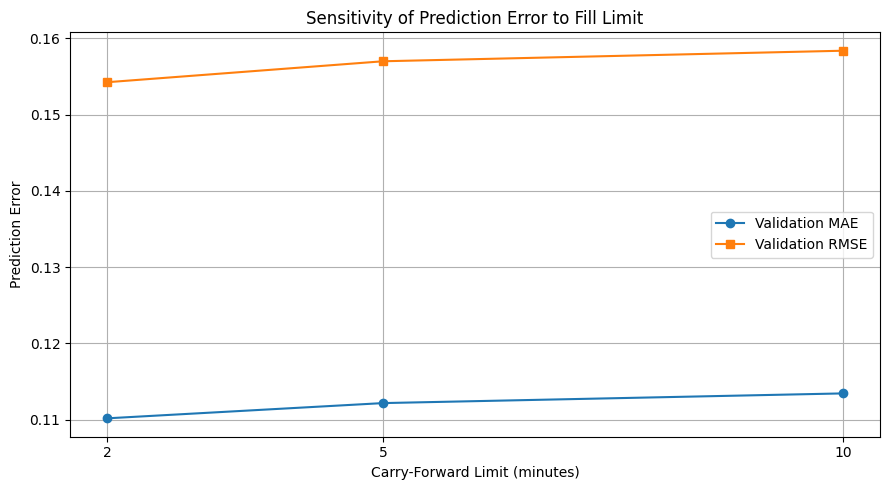

In [42]:

plt.figure(figsize=(9, 5))

plt.plot(
    sensitivity_df['Fill Limit (min)'],
    sensitivity_df['MAE'],
    marker='o',
    label='Validation MAE'
)

plt.plot(
    sensitivity_df['Fill Limit (min)'],
    sensitivity_df['RMSE'],
    marker='s',
    label='Validation RMSE'
)

plt.xlabel('Carry-Forward Limit (minutes)')
plt.ylabel('Prediction Error')
plt.title('Sensitivity of Prediction Error to Fill Limit')

plt.xticks([2, 5, 10])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [43]:

# STEP 10D: Verification checks

data_5min = prepare_occupancy_data(5)

# Verify occupancy fractions remain physically meaningful
assert data_5min['occupancy_fraction'].between(0, 1).all()
assert data_5min['target'].between(0, 1).all()

# Verify timestamps are sorted and unique
assert data_5min.index.is_monotonic_increasing
assert data_5min.index.is_unique

# Verify the function rejects invalid inputs
try:
    prepare_occupancy_data(-1)
except ValueError:
    print("Invalid fill limit correctly rejected.")
else:
    raise AssertionError("Invalid fill limit was accepted")

# Verify reproducibility of preprocessing
data_repeat = prepare_occupancy_data(5)

pd.testing.assert_frame_equal(
    data_5min,
    data_repeat
)

print("All preprocessing verification checks passed.")


Invalid fill limit correctly rejected.
All preprocessing verification checks passed.


In [44]:

# STEP 11A: Computational performance comparison

import time
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Use the improved training and validation datasets
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=best_depth_v2,
        random_state=42
    )
}

n_repeats = 30
performance_results = []

# Persistence baseline requires no training
start = time.perf_counter()

for _ in range(n_repeats):
    baseline_predictions = X_val_v2[
        'current_occupancy'
    ].to_numpy(copy=True)

baseline_time = (
    time.perf_counter() - start
) / n_repeats

performance_results.append({
    'Model': 'Persistence Baseline',
    'Median Training Time (ms)': 0,
    'Median Prediction Time (ms)': baseline_time * 1000
})

for name, model in models.items():

    training_times = []
    prediction_times = []

    for _ in range(n_repeats):

        # Measure training time
        start = time.perf_counter()

        model.fit(X_train_v2, y_train_v2)

        training_times.append(
            time.perf_counter() - start
        )

        # Measure prediction time
        start = time.perf_counter()

        model.predict(X_val_v2)

        prediction_times.append(
            time.perf_counter() - start
        )

    performance_results.append({
        'Model': name,
        'Median Training Time (ms)':
            np.median(training_times) * 1000,
        'Median Prediction Time (ms)':
            np.median(prediction_times) * 1000
    })

performance_df = pd.DataFrame(performance_results)

display(performance_df)


,Model,Median Training Time (ms),Median Prediction Time (ms)
0,Persistence Baseline,0.000000,0.067651
1,Linear Regression,1.842909,1.017358
2,Decision Tree,3.521004,1.141207


### Computational Performance

Training and prediction times were measured to assess the computational requirements of the different models.

Each measurement was repeated 30 times, and the median was used to reduce the influence of occasional unusually slow runs.

All three approaches required relatively little computation for the dataset used, suggesting that the models could be suitable for lightweight short-term occupancy prediction applications. However, the measurements do not include data loading and preprocessing time.

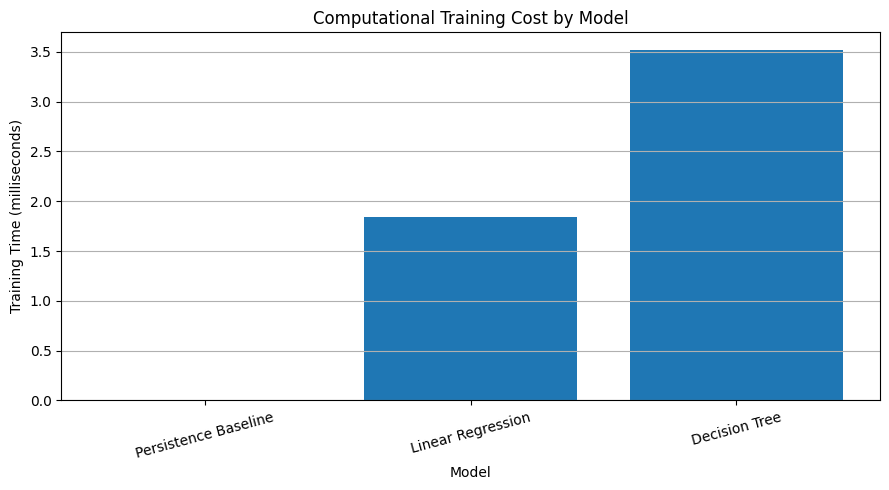

In [45]:

plt.figure(figsize=(9, 5))

plt.bar(
    performance_df['Model'],
    performance_df['Median Training Time (ms)']
)

plt.xlabel('Model')
plt.ylabel('Training Time (milliseconds)')
plt.title('Computational Training Cost by Model')

plt.xticks(rotation=15)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# Engineering Interpretation and Limitations

In [46]:

# STEP 12A: Analyse model prediction errors

# Create results using the existing final test predictions
engineering_results = pd.DataFrame({
    'Actual': y_test_v2,
    'Linear Regression': linear_test,
    'Decision Tree': tree_test,
    'Persistence Baseline': baseline_test
}, index=y_test_v2.index)

# Calculate signed errors
# Positive = underprediction
# Negative = overprediction

for model in [
    'Linear Regression',
    'Decision Tree',
    'Persistence Baseline'
]:
    engineering_results[model + ' Error'] = (
        engineering_results['Actual']
        - engineering_results[model]
    )

display(engineering_results.head())

# Summary of underprediction and overprediction
error_summary = []

for model in [
    'Linear Regression',
    'Decision Tree',
    'Persistence Baseline'
]:

    error = engineering_results[model + ' Error']

    error_summary.append({
        'Model': model,
        'Mean Underprediction Magnitude':
            error[error > 0].mean(),
        'Mean Overprediction Magnitude':
            -error[error < 0].mean(),
        'Underprediction Frequency (%)':
            100 * (error > 0).mean(),
        'Overprediction Frequency (%)':
            100 * (error < 0).mean()
    })

error_summary_df = pd.DataFrame(error_summary)

display(error_summary_df)


,Actual,Linear Regression,Decision Tree,Persistence Baseline,Linear Regression Error,Decision Tree Error,Persistence Baseline Error
collecteddate,,,,,,,
2024-10-06 14:00:00+11:00,0.666667,0.699401,0.702667,0.800000,-0.032734,-0.036000,-0.133333
2024-10-06 14:15:00+11:00,1.000000,0.671903,0.727687,0.666667,0.328097,0.272313,0.333333
2024-10-06 14:30:00+11:00,1.000000,0.841337,0.966965,1.000000,0.158663,0.033035,0.000000
2024-10-06 14:45:00+11:00,1.000000,0.898382,0.966965,1.000000,0.101618,0.033035,0.000000
2024-10-06 15:00:00+11:00,0.933333,0.898382,0.966965,1.000000,0.034951,-0.033632,-0.066667


,Model,Mean Underprediction Magnitude,Mean Overprediction Magnitude,Underprediction Frequency (%),Overprediction Frequency (%)
0,Linear Regression,0.100467,0.184205,62.950820,37.049180
1,Decision Tree,0.103573,0.177356,63.606557,36.393443
2,Persistence Baseline,0.187746,0.203444,32.950820,31.639344


In [47]:

# STEP 12B: Significant underprediction analysis

high_occupancy_threshold = 0.8
underprediction_threshold = 0.3

high_occupancy = (
    engineering_results['Actual']
    >= high_occupancy_threshold
)

print(
    "High-occupancy test intervals:",
    high_occupancy.sum()
)

underprediction_results = []

for model in [
    'Linear Regression',
    'Decision Tree',
    'Persistence Baseline'
]:

    errors = engineering_results['Actual'] - engineering_results[model]

    significant_underprediction = (
        high_occupancy &
        (errors >= underprediction_threshold)
    )

    count = significant_underprediction.sum()

    # Percentage of high-occupancy intervals
    if high_occupancy.sum() > 0:
        rate = 100 * count / high_occupancy.sum()
    else:
        rate = np.nan

    underprediction_results.append({
        'Model': model,
        'Significant Underpredictions': count,
        'High Occupancy Intervals': high_occupancy.sum(),
        'Underprediction Rate (%)': rate
    })

underprediction_df = pd.DataFrame(
    underprediction_results
)

display(underprediction_df)


High-occupancy test intervals: 411


,Model,Significant Underpredictions,High Occupancy Intervals,Underprediction Rate (%)
0,Linear Regression,22,411,5.352798
1,Decision Tree,19,411,4.622871
2,Persistence Baseline,31,411,7.542579


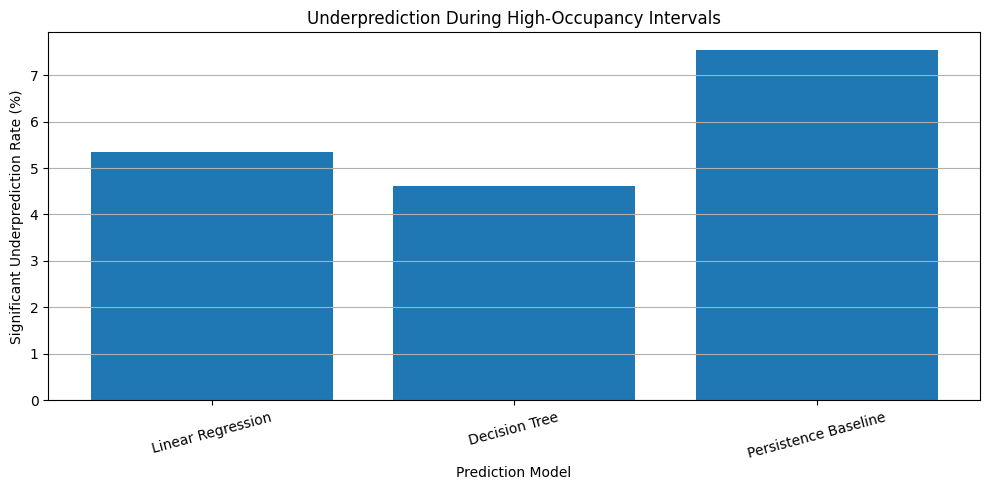

In [48]:

# STEP 12C: Visualise significant underprediction rates

plt.figure(figsize=(10, 5))

plt.bar(
    underprediction_df['Model'],
    underprediction_df['Underprediction Rate (%)']
)

plt.xlabel('Prediction Model')
plt.ylabel('Significant Underprediction Rate (%)')

plt.title(
    'Underprediction During High-Occupancy Intervals'
)

plt.xticks(rotation=15)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


,count,mean
Occupancy Level,,
Low,33,0.351475
Medium,140,0.194472
High,437,0.094702


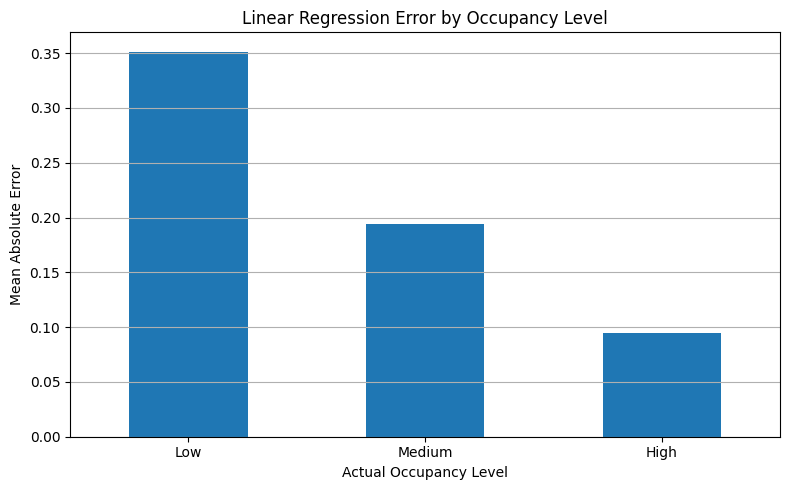

In [49]:

# STEP 12D: Linear Regression errors by occupancy level

results = engineering_results.copy()

# Categorise actual occupancy
results['Occupancy Level'] = pd.cut(
    results['Actual'],
    bins=[-0.01, 0.3, 0.7, 1.01],
    labels=['Low', 'Medium', 'High']
)

# Calculate absolute prediction error
results['Absolute Error'] = abs(
    results['Actual'] - results['Linear Regression']
)

# Average errors by occupancy level
grouped_errors = results.groupby(
    'Occupancy Level',
    observed=True
)['Absolute Error'].agg(['count', 'mean'])

display(grouped_errors)

# Visualise
plt.figure(figsize=(8, 5))

grouped_errors['mean'].plot(
    kind='bar'
)

plt.xlabel('Actual Occupancy Level')
plt.ylabel('Mean Absolute Error')
plt.title('Linear Regression Error by Occupancy Level')

plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


# Final Code Verification and Reproducibility

In [50]:

# STEP 13A: Verify model-ready dataset

# Check chronological order
assert data.index.is_monotonic_increasing
assert data.index.is_unique

# Check occupancy values
assert data['occupancy_fraction'].between(0, 1).all()
assert data['target'].between(0, 1).all()

# Check missing values
assert data[features + ['target']].notna().all().all()

# Check input and output dimensions
assert len(X) == len(y)
assert len(X_train_v2) == len(y_train_v2)
assert len(X_val_v2) == len(y_val_v2)
assert len(X_test_v2) == len(y_test_v2)

print("All dataset verification checks passed.")


All dataset verification checks passed.


In [51]:

# STEP 13B: Verify forecasting structure

# Verify target is the next 15-minute interval
expected_target = occupancy_15min[
    'occupancy_fraction'
].shift(-1).reindex(data.index)

np.testing.assert_allclose(
    data['target'].values,
    expected_target.values
)

# Verify previous occupancy input
expected_previous = occupancy_15min[
    'occupancy_fraction'
].shift(1).reindex(data.index)

np.testing.assert_allclose(
    data['previous_occupancy'].values,
    expected_previous.values
)

# Verify chronological separation
assert X_train_v2.index.max() < X_val_v2.index.min()
assert X_val_v2.index.max() < X_test_v2.index.min()

# Check actual separations
train_val_gap = (
    X_val_v2.index.min() - X_train_v2.index.max()
)

val_test_gap = (
    X_test_v2.index.min() - X_val_v2.index.max()
)

print("Training-validation separation:", train_val_gap)
print("Validation-testing separation:", val_test_gap)

# Conservative separation requirement
assert train_val_gap >= pd.Timedelta(hours=1)
assert val_test_gap >= pd.Timedelta(hours=1)

print("Forecasting and chronological separation checks passed.")


Training-validation separation: 0 days 04:30:00
Validation-testing separation: 0 days 03:45:00
Forecasting and chronological separation checks passed.


In [52]:

# STEP 13C: Reproducibility verification

# Repeat preprocessing
repeat_data = prepare_occupancy_data(5)

pd.testing.assert_frame_equal(
    data,
    repeat_data
)

# Repeat Decision Tree training
repeat_tree = DecisionTreeRegressor(
    max_depth=best_depth_v2,
    random_state=42
)

repeat_tree.fit(X_train_v2, y_train_v2)

# Compare predictions
original_predictions = best_tree_v2.predict(X_val_v2)
repeat_predictions = repeat_tree.predict(X_val_v2)

np.testing.assert_allclose(
    original_predictions,
    repeat_predictions
)

print("Preprocessing and model training are reproducible.")


Preprocessing and model training are reproducible.


# Source Code Organisation and Documentation

In [53]:

#Create preprocessing.py

from pathlib import Path

# Create the source code directory
Path("src").mkdir(exist_ok=True)

# Write the preprocessing module
preprocessing_code = '''
"""Functions for preparing building occupancy sensor data."""

import numpy as np
import pandas as pd


def prepare_occupancy_data(clean_data, fill_limit=5):
    """
    Convert irregular occupancy readings into model-ready data.

    Parameters
    ----------
    clean_data : pandas.DataFrame
        DataFrame with a DatetimeIndex and an 'occupied' column
        containing binary occupancy values (0 or 1).
    fill_limit : int, optional
        Maximum number of missing one-minute intervals to fill.
        Default is 5 minutes.

    Returns
    -------
    pandas.DataFrame
        Occupancy fractions, time-based features and prediction
        targets for the following 15-minute interval.

    Raises
    ------
    ValueError
        If fill_limit is invalid or required data is missing.
    """
    if not isinstance(fill_limit, int) or fill_limit < 0:
        raise ValueError("fill_limit must be a non-negative integer")

    if 'occupied' not in clean_data.columns:
        raise ValueError("Missing required column: occupied")

    if not isinstance(clean_data.index, pd.DatetimeIndex):
        raise ValueError("Data must have a DatetimeIndex")

    # Convert readings into one-minute intervals
    minute_series = (
        clean_data['occupied']
        .sort_index()
        .resample('1min')
        .last()
    )

    # Carry previous occupancy state forward
    if fill_limit > 0:
        minute_series = minute_series.ffill(limit=fill_limit)

    # Aggregate into 15-minute occupancy fractions
    intervals = minute_series.resample('15min').agg(
        ['mean', 'count']
    )

    intervals.columns = [
        'occupancy_fraction',
        'valid_minutes'
    ]

    # Require at least 12 valid minutes per interval
    intervals.loc[
        intervals['valid_minutes'] < 12,
        'occupancy_fraction'
    ] = np.nan

    result = intervals[['occupancy_fraction']].copy()

    # Create model input features
    result['current_occupancy'] = result['occupancy_fraction']
    result['previous_occupancy'] = result['occupancy_fraction'].shift(1)

    # Next interval is the prediction target
    result['target'] = result['occupancy_fraction'].shift(-1)

    next_time = result.index + pd.Timedelta(minutes=15)

    result['hour'] = next_time.hour
    result['day_of_week'] = next_time.dayofweek
    result['weekend'] = (result['day_of_week'] >= 5).astype(int)

    return result.dropna().copy()
'''

# Save Python module
Path("src/preprocessing.py").write_text(preprocessing_code)

print("Created src/preprocessing.py")


Created src/preprocessing.py


In [55]:

# Test the preprocessing module

from src.preprocessing import prepare_occupancy_data

# Use the same sensor data from Step 6
processed_data = prepare_occupancy_data(
    clean_data,
    fill_limit=5
)

print("Processed samples:", len(processed_data))

display(processed_data.head())

# Compare with the original model-ready dataset
pd.testing.assert_frame_equal(
    processed_data,
    data
)

print("Preprocessing module matches original results!")


Processed samples: 4089


,occupancy_fraction,current_occupancy,previous_occupancy,target,hour,day_of_week,weekend
collecteddate,,,,,,,
2024-07-22 08:30:00+10:00,1.000000,1.000000,1.000000,0.933333,8,0,0
2024-07-22 08:45:00+10:00,0.933333,0.933333,1.000000,1.000000,9,0,0
2024-07-22 09:00:00+10:00,1.000000,1.000000,0.933333,1.000000,9,0,0
2024-07-22 09:15:00+10:00,1.000000,1.000000,1.000000,1.000000,9,0,0
2024-07-22 09:30:00+10:00,1.000000,1.000000,1.000000,1.000000,9,0,0


Preprocessing module matches original results!


In [56]:

# Step 14B.3 - Create models.py

from pathlib import Path

models_code = '''
"""Machine learning models for predicting building occupancy."""

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor


def train_linear_model(X_train, y_train):
    """
    Train a Linear Regression model.

    Parameters
    ----------
    X_train : pandas.DataFrame
        Training input features.
    y_train : pandas.Series
        Actual occupancy fractions between 0 and 1.

    Returns
    -------
    sklearn.linear_model.LinearRegression
        Trained Linear Regression model.
    """
    model = LinearRegression()
    model.fit(X_train, y_train)

    return model


def train_decision_tree(X_train, y_train, max_depth=5):
    """
    Train a Decision Tree Regression model.

    Parameters
    ----------
    X_train : pandas.DataFrame
        Training input features.
    y_train : pandas.Series
        Actual occupancy fractions.
    max_depth : int
        Maximum depth of the decision tree.

    Returns
    -------
    sklearn.tree.DecisionTreeRegressor
        Trained Decision Tree model.
    """
    if not isinstance(max_depth, int) or max_depth < 1:
        raise ValueError("max_depth must be a positive integer")

    model = DecisionTreeRegressor(
        max_depth=max_depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    return model


def predict_occupancy(model, X):
    """
    Predict occupancy fractions using a trained model.

    Parameters
    ----------
    model : fitted regression model
        A trained model supporting predict().
    X : pandas.DataFrame
        Input features to make predictions on.

    Returns
    -------
    numpy.ndarray
        Predicted occupancy fractions clipped between 0 and 1.
    """
    predictions = model.predict(X)

    return np.clip(predictions, 0, 1)
'''

Path("src/models.py").write_text(models_code)

print("Created src/models.py")


Created src/models.py


In [57]:

# Step 14B.4 - Verify models.py

from src.models import (
    train_linear_model,
    train_decision_tree,
    predict_occupancy
)

# Train models using the improved chronological split
linear_module = train_linear_model(
    X_train_v2,
    y_train_v2
)

tree_module = train_decision_tree(
    X_train_v2,
    y_train_v2,
    max_depth=best_depth_v2
)

# Generate validation predictions
linear_module_pred = predict_occupancy(
    linear_module,
    X_val_v2
)

tree_module_pred = predict_occupancy(
    tree_module,
    X_val_v2
)

# Compare against original predictions
np.testing.assert_allclose(
    linear_module_pred,
    linear_pred_v2
)

np.testing.assert_allclose(
    tree_module_pred,
    tree_pred_v2
)

print("Model module matches original predictions!")


Model module matches original predictions!


In [58]:

# Step 14B.5 - Create evaluation.py

evaluation_code = '''
"""Performance evaluation functions for occupancy prediction."""

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error


def evaluate_regression(y_true, y_pred):
    """
    Calculate occupancy prediction error metrics.

    Parameters
    ----------
    y_true : array-like
        Actual occupancy fractions.
    y_pred : array-like
        Predicted occupancy fractions.

    Returns
    -------
    dict
        Dictionary containing MAE and RMSE.
    """
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }


def significant_underprediction_rate(
    y_true,
    y_pred,
    high_threshold=0.8,
    error_threshold=0.3
):
    """
    Calculate significant underprediction during high occupancy.

    Parameters
    ----------
    y_true : array-like
        Actual occupancy fractions.
    y_pred : array-like
        Predicted occupancy fractions.
    high_threshold : float
        Minimum actual fraction considered high occupancy.
    error_threshold : float
        Minimum underprediction magnitude considered significant.

    Returns
    -------
    float
        Percentage of high-occupancy observations with
        significant underprediction. Returns NaN if there
        are no high-occupancy observations.
    """
    actual = np.asarray(y_true)
    predicted = np.asarray(y_pred)

    high_occupancy = actual >= high_threshold

    if high_occupancy.sum() == 0:
        return np.nan

    significant_errors = (
        high_occupancy &
        ((actual - predicted) >= error_threshold)
    )

    return 100 * significant_errors.sum() / high_occupancy.sum()
'''

Path("src/evaluation.py").write_text(evaluation_code)

print("Created src/evaluation.py")


Created src/evaluation.py


In [59]:

# Verify evaluation.py

from src.evaluation import (
    evaluate_regression,
    significant_underprediction_rate
)

# Verify accuracy metrics
metrics = evaluate_regression(
    y_test_v2,
    linear_test
)

print("Linear Regression test metrics:")
print(metrics)

# Verify significant underprediction
underprediction = significant_underprediction_rate(
    y_test_v2,
    linear_test
)

print(
    "Significant underprediction rate:",
    round(underprediction, 4),
    "%"
)

# Check against the original test results
assert np.isclose(metrics["MAE"], 0.131491, atol=0.000001)
assert np.isclose(metrics["RMSE"], 0.183799, atol=0.000001)

assert np.isclose(
    underprediction,
    5.352798,
    atol=0.0001
)

print("Evaluation module matches original results!")


Linear Regression test metrics:
{'MAE': 0.1314910763586182, 'RMSE': np.float64(0.183799065400001)}
Significant underprediction rate: 5.3528 %
Evaluation module matches original results!


In [ ]:

# Package Python source files

import shutil
from google.colab import files
from pathlib import Path

# Check all source files exist
source_files = [
    "src/preprocessing.py",
    "src/models.py",
    "src/evaluation.py"
]

for file in source_files:
    assert Path(file).exists(), f"Missing: {file}"

# Create a ZIP containing the src folder
shutil.make_archive(
    "/content/mma3001_source",
    "zip",
    root_dir="/content",
    base_dir="src"
)

# Download ZIP to your computer
files.download("/content/mma3001_source.zip")


In [60]:

# Step 14C.1 - Package Python source files

import shutil
from google.colab import files
from pathlib import Path

# Check all source files exist
source_files = [
    "src/preprocessing.py",
    "src/models.py",
    "src/evaluation.py"
]

for file in source_files:
    assert Path(file).exists(), f"Missing: {file}"

# Create a ZIP containing the src folder
shutil.make_archive(
    "/content/mma3001_source",
    "zip",
    root_dir="/content",
    base_dir="src"
)

# Download ZIP to your computer
files.download("/content/mma3001_source.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Automated Testing Using pytest

In [61]:

# Step 15A - Install testing libraries

%pip install -q pytest pytest-html


In [62]:

# Step 15B - Create automated tests

from pathlib import Path

Path("tests").mkdir(exist_ok=True)

test_code = '''
"""Automated tests for the occupancy prediction project."""

import numpy as np
import pandas as pd
import pytest

from src.preprocessing import prepare_occupancy_data
from src.models import (
    train_linear_model,
    train_decision_tree,
    predict_occupancy
)
from src.evaluation import (
    evaluate_regression,
    significant_underprediction_rate
)


def test_preprocessing_output():
    """Verify processed occupancy values and feature columns."""
    index = pd.date_range(
        "2024-08-05",
        periods=180,
        freq="1min",
        tz="Australia/Melbourne"
    )

    sensor = pd.DataFrame(
        {"occupied": [1] * 90 + [0] * 90},
        index=index
    )

    result = prepare_occupancy_data(sensor, fill_limit=5)

    assert not result.empty
    assert result["occupancy_fraction"].between(0, 1).all()
    assert result["target"].between(0, 1).all()
    assert result.index.is_monotonic_increasing
    assert result.index.is_unique


def test_invalid_fill_limit():
    """Reject negative carry-forward limits."""
    index = pd.date_range("2024-08-05", periods=30, freq="1min")
    sensor = pd.DataFrame({"occupied": [1] * 30}, index=index)

    with pytest.raises(ValueError):
        prepare_occupancy_data(sensor, fill_limit=-1)


def test_missing_column():
    """Reject sensor data without an occupied column."""
    index = pd.date_range("2024-08-05", periods=30, freq="1min")
    sensor = pd.DataFrame({"headcount": [1] * 30}, index=index)

    with pytest.raises(ValueError):
        prepare_occupancy_data(sensor)


def test_linear_regression():
    """Verify Linear Regression predictions are bounded."""
    X = pd.DataFrame({"hour": [8, 9, 10, 11, 12]})
    y = pd.Series([0.1, 0.3, 0.6, 0.9, 1.0])

    model = train_linear_model(X, y)
    predictions = predict_occupancy(model, X)

    assert len(predictions) == len(y)
    assert np.all((predictions >= 0) & (predictions <= 1))


def test_decision_tree_reproducibility():
    """Verify deterministic Decision Tree predictions."""
    X = pd.DataFrame({"hour": [8, 9, 10, 11, 12]})
    y = pd.Series([0.1, 0.3, 0.6, 0.9, 1.0])

    model1 = train_decision_tree(X, y, max_depth=3)
    model2 = train_decision_tree(X, y, max_depth=3)

    np.testing.assert_allclose(
        predict_occupancy(model1, X),
        predict_occupancy(model2, X)
    )


def test_invalid_tree_depth():
    """Reject a tree with non-positive maximum depth."""
    X = pd.DataFrame({"hour": [8, 9, 10]})
    y = pd.Series([0.1, 0.5, 0.9])

    with pytest.raises(ValueError):
        train_decision_tree(X, y, max_depth=0)


def test_evaluation_metrics():
    """Verify MAE and RMSE against manually calculated values."""
    actual = np.array([0.0, 1.0])
    predicted = np.array([0.2, 0.8])

    result = evaluate_regression(actual, predicted)

    assert np.isclose(result["MAE"], 0.2)
    assert np.isclose(result["RMSE"], 0.2)


def test_underprediction_rate():
    """Verify significant underprediction rate."""
    actual = np.array([0.9, 0.9, 0.1])
    predicted = np.array([0.4, 0.8, 0.1])

    rate = significant_underprediction_rate(actual, predicted)

    assert np.isclose(rate, 50.0)
'''

Path("tests/test_project.py").write_text(test_code)

# Ensure Python recognises src as a package
Path("src/__init__.py").touch(exist_ok=True)

print("Created tests/test_project.py")


Created tests/test_project.py


In [63]:

# Step 15C - Run automated tests

import subprocess
import sys

Path("results").mkdir(exist_ok=True)

command = [
    sys.executable,
    "-m", "pytest",
    "tests/test_project.py",
    "-v",
    "--html=results/test_report.html",
    "--self-contained-html"
]

completed = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print(completed.stdout)
print(completed.stderr)

if completed.returncode != 0:
    raise RuntimeError("One or more tests failed")

print("All tests passed. HTML report generated.")


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
metadata: {'Python': '3.13.16', 'Platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'Packages': {'pytest': '8.4.2', 'pluggy': '1.7.0'}, 'Plugins': {'html': '4.2.0', 'metadata': '3.1.1', 'platformdirs': '4.13.5', 'anyio': '4.15.1', 'typeguard': '4.6.0', 'langsmith': '0.14.11'}}
rootdir: /content
plugins: html-4.2.0, metadata-3.1.1, platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.11
collecting ... collected 8 items

tests/test_project.py::test_preprocessing_output PASSED                  [ 12%]
tests/test_project.py::test_invalid_fill_limit PASSED                    [ 25%]
tests/test_project.py::test_missing_column PASSED                        [ 37%]
tests/test_project.py::test_linear_regression PASSED                     [ 50%]
tests/test_project.py::test_decision_tree_reproducibility

In [64]:

# Package tests and report

import shutil
from google.colab import files

# Create a folder with deliverables
package = Path("/content/mma3001_testing")
package.mkdir(exist_ok=True)

shutil.copy("tests/test_project.py", package / "test_project.py")
shutil.copy("results/test_report.html", package / "test_report.html")

shutil.make_archive(
    "/content/mma3001_testing",
    "zip",
    root_dir="/content/mma3001_testing"
)

files.download("/content/mma3001_testing.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# HTML Source Code Documentation

In [65]:
# Step 16A - Install pdoc

%pip install -q pdoc

In [67]:
# Generate HTML documentation

import subprocess
import sys
from pathlib import Path

# Create the documentation folder
Path("docs/html").mkdir(parents=True, exist_ok=True)

# Generate HTML pages from the module docstrings
command = [
    sys.executable,
    "-m", "pdoc",
    "src.preprocessing",
    "src.models",
    "src.evaluation",
    "-o", "docs/html"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("pdoc documentation generation failed")

print("HTML documentation generated successfully!")
print("Generated files:")

for file in sorted(Path("docs/html").rglob("*.html")):
    print(file)



HTML documentation generated successfully!
Generated files:
docs/html/index.html
docs/html/src/evaluation.html
docs/html/src/models.html
docs/html/src/preprocessing.html


In [68]:
#  Download HTML documentation

import shutil
from google.colab import files

# Package the entire documentation folder,
# preserving its internal folder structure
shutil.make_archive(
    "/content/mma3001_documentation",
    "zip",
    root_dir="/content/docs",
    base_dir="html"
)

files.download("/content/mma3001_documentation.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>